# Clustering des pages du Soir, années 1940

## Imports

In [1]:
import collections
import os
import string
import sys

import pandas as pd
from nltk import word_tokenize
from nltk.corpus import stopwords
from pprint import pprint
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.stats import chi2_contingency
import seaborn as sns

In [2]:
import nltk

nltk.download('punkt')
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\DERRICK\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\DERRICK\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [3]:
data_path =  "../../data/txt/"

## Choisir une décennie

In [4]:
DECADE = '1940'

## Charger tous les  fichiers de la décennie et en créer une liste de textes

In [5]:
files = [f for f in sorted(os.listdir(data_path)) if f"_{DECADE[:-1]}" in f]

In [6]:
# Exemple de fichiers
files[:5]

['KB_JB838_1940-01-04_01-00001.txt',
 'KB_JB838_1940-01-05_01-00009.txt',
 'KB_JB838_1940-01-07_01-00014.txt',
 'KB_JB838_1940-01-10_01-00003.txt',
 'KB_JB838_1940-01-11_01-00004.txt']

In [7]:
texts = []
for f in files:
    with open(data_path + f, "r", encoding="utf-8") as fh:
        texts.append(fh.read())
len(texts)

1000

In [8]:
# Exemple de textes
texts[0][:400]

"54 e ANNEE. — N° 4. Pages - 40 C 1 *® 8 Grand-Duché : 45 centimes. - France : 75 centime». ABONNEMENTS pour la province on Province } s'abonne à là Poste CH' Vüle au $ pour | T , oi , ŒOl# 28>50 BUREAUX ET FILS SPÉCIAUX: — — ■ ; S Un an 170.00 Congo • j Six mol , 85X0 Etranger : Prix euivant conventions VENTE ET ABONNEM. : PLACE DE LOUVAIN. 23 □ SALLE DE DÉPÊCHES : 124. RUE ROYALE BRUXELLES G “ ■“"

## Vectoriser les documents à l'aide de TF-IDF

In [9]:
# Création d'une fonction de pré-traitement
def preprocessing(text):
    """Découpe le texte en mots après avoir retiré la ponctuation"""
    punctuation = string.punctuation + "’‘«»“”—–…°®•"
    text = text.translate(str.maketrans('', '', punctuation))
    tokens = word_tokenize(text, language='french')
    return tokens

### Instancier le modèle TF-IDF avec ses arguments

In [10]:
vectorizer = TfidfVectorizer(
    tokenizer=preprocessing,
    stop_words=stopwords.words('french'),
    max_df=0.5,
    min_df=0.1,
    lowercase=True)

### Construire la matrice de vecteurs à l'aide de la fonction `fit_transform`

In [11]:
tfidf_vectors = vectorizer.fit_transform(texts)

c:\Users\DERRICK\tac\.venv\Lib\site-packages\sklearn\feature_extraction\text.py:527: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [12]:
# Détail de la matrice
tfidf_vectors

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 940483 stored elements and shape (1000, 4613)>

### Imprimer le vecteur tf-IDF du premier document

In [13]:
pd.Series(
    tfidf_vectors[0].toarray()[0],
    index=vectorizer.get_feature_names_out()
    ).sort_values(ascending=False)

gouvernement    0.158981
milieux         0.155027
cabinet         0.133183
litalie         0.126929
neige           0.118391
                  ...   
107             0.000000
106             0.000000
1050            0.000000
105             0.000000
05              0.000000
Length: 4613, dtype: float64

## Comprendre les vecteurs et leurs "distances"

In [14]:
cosine([1, 2, 3], [1, 2, 3])

np.float64(0.0)

In [15]:
cosine([1, 2, 3], [1, 2, 2])

np.float64(0.02004211298777725)

In [16]:
cosine([1, 2, 3], [2, 2, 2])

np.float64(0.07417990022744858)

### Tests sur nos documents

In [17]:
tfidf_array = tfidf_vectors.toarray()

In [18]:
# Vecteur du document 0
tfidf_array[0]

array([0.01764576, 0.        , 0.        , ..., 0.        , 0.        ,
       0.        ], shape=(4613,))

In [19]:
# Vecteur du document 1
tfidf_array[1]

array([0.        , 0.        , 0.        , ..., 0.00663599, 0.00738525,
       0.        ], shape=(4613,))

In [20]:
cosine(tfidf_array[0], tfidf_array[1])

np.float64(0.9508306242957922)

## Appliquer un algorithme de clustering sur les vecteurs TF-IDF des documents

Pour en savoir plus sur le KMeans clustering :
- https://medium.com/dataseries/k-means-clustering-explained-visually-in-5-minutes-b900cc69d175

### Définir un nombre de clusters

In [21]:
N_CLUSTERS = 5

### Instancier le modèle K-Means et ses arguments

In [22]:
km_model = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)

### Appliquer le clustering à l'aide de la fonction `fit_predict`

In [23]:
clusters = km_model.fit_predict(tfidf_vectors)

In [24]:
clustering = collections.defaultdict(list)

for idx, label in enumerate(clusters):
    clustering[label].append(files[idx])

In [25]:
pprint(dict(clustering))

{np.int32(0): ['KB_JB838_1940-01-19_01-00005.txt',
               'KB_JB838_1940-02-06_01-00005.txt',
               'KB_JB838_1940-02-07_01-00005.txt',
               'KB_JB838_1940-02-09_01-00005.txt',
               'KB_JB838_1940-02-12_01-00005.txt',
               'KB_JB838_1940-03-04_01-00005.txt',
               'KB_JB838_1940-04-22_01-00005.txt',
               'KB_JB838_1940-08-02_01-00004.txt',
               'KB_JB838_1940-10-08_01-00005.txt',
               'KB_JB838_1940-10-29_01-00006.txt',
               'KB_JB838_1940-11-05_01-00005.txt',
               'KB_JB838_1940-11-07_01-00005.txt',
               'KB_JB838_1940-12-09_01-00004.txt',
               'KB_JB838_1940-12-11_01-00008.txt',
               'KB_JB838_1941-01-28_01-00005.txt',
               'KB_JB838_1941-03-15_01-00005.txt',
               'KB_JB838_1941-03-17_01-00006.txt',
               'KB_JB838_1941-04-04_01-00008.txt',
               'KB_JB838_1941-05-01_01-00008.txt',
               'KB_JB838_1941-0

## Visualiser les clusters

### Réduire les vecteurs à 2 dimensions à l'aide de l'algorithme PCA
Cette étape est nécessaire afin de visualiser les documents dans un espace 2D

https://fr.wikipedia.org/wiki/Analyse_en_composantes_principales

In [26]:
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(tfidf_vectors.toarray())

In [27]:
reduced_vectors[:10]

array([[-0.25984243,  0.16489535],
       [ 0.61807599,  0.18997723],
       [ 0.11269759, -0.07913255],
       [-0.29866139,  0.28004252],
       [-0.26240906,  0.11728442],
       [-0.19361525, -0.15157665],
       [-0.27928356,  0.17746249],
       [-0.25954733,  0.14848398],
       [-0.11527349, -0.17584424],
       [ 0.45227659,  0.04090507]])

### Générer le plot

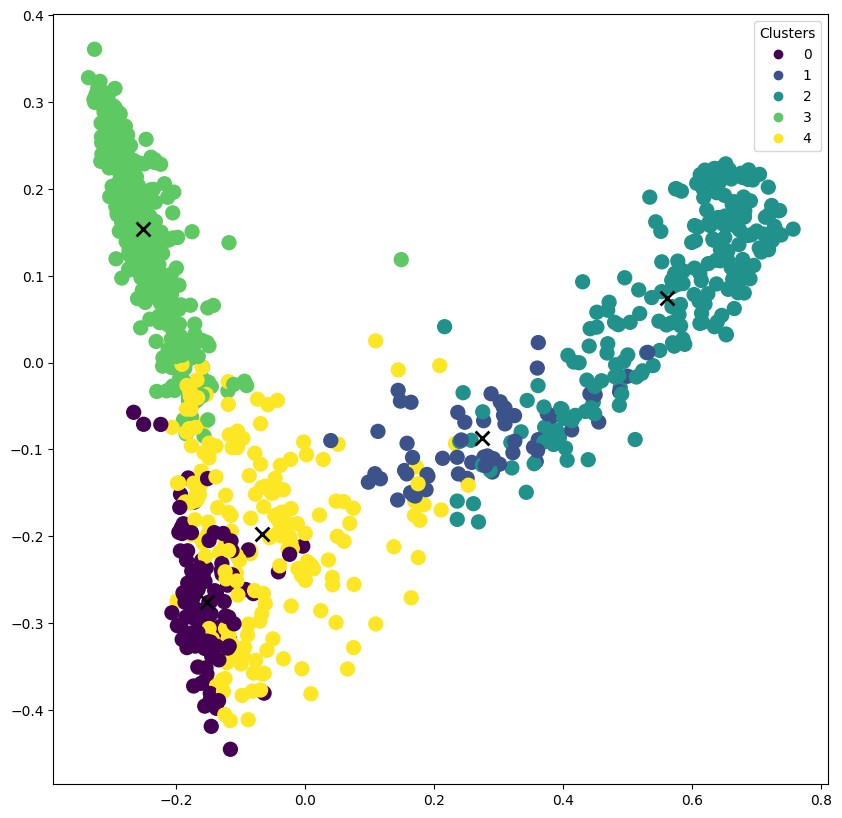

In [28]:
x_axis = reduced_vectors[:, 0]
y_axis = reduced_vectors[:, 1]

plt.figure(figsize=(10,10))
scatter = plt.scatter(x_axis, y_axis, s=100, c=clusters)

# Ajouter les centroïdes
centroids = pca.transform(km_model.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1],  marker = "x", s=100, linewidths = 2, color='black')

# Ajouter la légende
plt.legend(handles=scatter.legend_elements()[0], labels=set(clusters), title="Clusters")

## Interpréter les clusters

Pour chaque cluster, j'affiche son nombre de pages, les 15 mots qui pèsent le plus dans son centre, puis la répartition de ses pages par année.

In [29]:
# Nombre de pages et mots les plus caractéristiques de chaque cluster
terms = vectorizer.get_feature_names_out()
counts = collections.Counter(clusters)

for i, center in enumerate(km_model.cluster_centers_):
    top = center.argsort()[::-1][:15]
    print(f"Cluster {i} ({counts[i]} pages) :", ", ".join(terms[j] for j in top))

Cluster 0 (121 pages) : match, course, bat, division, mètres, mutuel, pts, points, classement, championnat, équipes, champion, léquipe, finale, vainqueur
Cluster 1 (60 pages) : vend, hp, ford, cv, vendre, ag, rossel, z, chevrolet, pneus, ecr, cyl, ecrire, renault, int
Cluster 2 (210 pages) : dem, rossel, ag, ecr, ecrire, ec, ecagrossel, app, louer, mod, cherche, agrossel, conf, vendre, agence
Cluster 3 (407 pages) : gouvernement, ministre, politique, troupes, allemands, etatsunis, forces, britannique, berlin, lallemagne, front, allemande, militaire, janvier, soviétique
Cluster 4 (202 pages) : ps, cap, notaire, mod, ca, admis, dannoncer, etude, décès, juin, prie, katanga, ena, faç, enf


In [30]:
# Répartition des pages de chaque cluster par année
for i in range(N_CLUSTERS):
    years = collections.Counter(files[j].split('_')[2][:4] for j in range(len(files)) if clusters[j] == i)
    print(f"Cluster {i} :", dict(sorted(years.items())))

Cluster 0 : {'1940': 14, '1941': 13, '1942': 18, '1943': 16, '1944': 4, '1945': 2, '1946': 9, '1947': 16, '1948': 11, '1949': 18}
Cluster 1 : {'1940': 6, '1941': 5, '1946': 10, '1947': 15, '1948': 11, '1949': 13}
Cluster 2 : {'1940': 16, '1941': 18, '1942': 18, '1943': 10, '1944': 22, '1945': 36, '1946': 22, '1947': 24, '1948': 25, '1949': 19}
Cluster 3 : {'1940': 42, '1941': 41, '1942': 44, '1943': 41, '1944': 50, '1945': 50, '1946': 39, '1947': 31, '1948': 35, '1949': 34}
Cluster 4 : {'1940': 22, '1941': 23, '1942': 20, '1943': 33, '1944': 24, '1945': 12, '1946': 20, '1947': 14, '1948': 18, '1949': 16}
